# Contribution by depth climatology

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

In [2]:
# bring in water mass fraction data - focusing on depths between 50 and 200 m
dropcol = ['dep0_1', 'dep1_2', 'dep2_3', 'dep3_4', 'dep4_5', 'dep5_6',
       'dep6_7', 'dep7_8', 'dep8_9', 'dep9_10', 'dep10_11', 'dep11_12',
       'dep12_13', 'dep13_14', 'dep14_15', 'dep15_16', 'dep16_17', 'dep17_18',
       'dep18_20', 'dep20_22', 'dep22_25', 'dep25_31', 'dep31_39', 'dep39_50',
       'dep212_239', 'dep239_266', 'dep266_293','dep293_320', 'dep320_347', 
       'dep347_374', 'dep374_401', 'dep401_428','dep428_454']
floop = pd.read_csv('./boundarymaking/output/inflowfraction_D_loop.csv').drop(columns=['Unnamed: 0']).drop(columns=dropcol)
ffresh = pd.read_csv('./boundarymaking/output/inflowfraction_D_fresh.csv').drop(columns=['Unnamed: 0']).drop(columns=dropcol)
fsouth = pd.read_csv('./boundarymaking/output/inflowfraction_D_south.csv').drop(columns=['Unnamed: 0']).drop(columns=dropcol)
fcuc = pd.read_csv('./boundarymaking/output/inflowfraction_D_cuc.csv').drop(columns=['Unnamed: 0']).drop(columns=dropcol)
foffD = pd.read_csv('./boundarymaking/output/inflowfraction_D_offD.csv').drop(columns=['Unnamed: 0']).drop(columns=dropcol)
foffS = pd.read_csv('./boundarymaking/output/inflowfraction_D_offS.csv').drop(columns=['Unnamed: 0']).drop(columns=dropcol)
fnorth = pd.read_csv('./boundarymaking/output/inflowfraction_D_north.csv').drop(columns=['Unnamed: 0']).drop(columns=dropcol)

In [3]:
floop['month'] = [int(floop.day[i][5:7]) for i in range(len(floop))]
fcuc['month'] = [int(fcuc.day[i][5:7]) for i in range(len(floop))]
ffresh['month'] = [int(ffresh.day[i][5:7]) for i in range(len(floop))]
fsouth['month'] = [int(fsouth.day[i][5:7]) for i in range(len(floop))]
foffD['month'] = [int(foffD.day[i][5:7]) for i in range(len(floop))]
foffS['month'] = [int(foffS.day[i][5:7]) for i in range(len(floop))]
fnorth['month'] = [int(fnorth.day[i][5:7]) for i in range(len(floop))]


In [4]:
looclim = floop.drop(columns=['day']).groupby(["month"]).mean()
cucclim = fcuc.drop(columns=['day']).groupby(["month"]).mean()
freclim = ffresh.drop(columns=['day']).groupby(["month"]).mean()
souclim = fsouth.drop(columns=['day']).groupby(["month"]).mean()
ofDclim = foffD.drop(columns=['day']).groupby(["month"]).mean()
ofSclim = foffS.drop(columns=['day']).groupby(["month"]).mean()
norclim = fnorth.drop(columns=['day']).groupby(["month"]).mean()


In [5]:
columns = norclim.columns
columns

Index(['dep50_67', 'dep67_86', 'dep86_109', 'dep109_134', 'dep134_160',
       'dep160_186', 'dep186_212'],
      dtype='str')

In [6]:
depthsep = [51.5,67.5,87.3,110.0,134.5,160.1,186.3,212.9]
cellheight = np.array(depthsep[1:]) - np.array(depthsep[:-1])

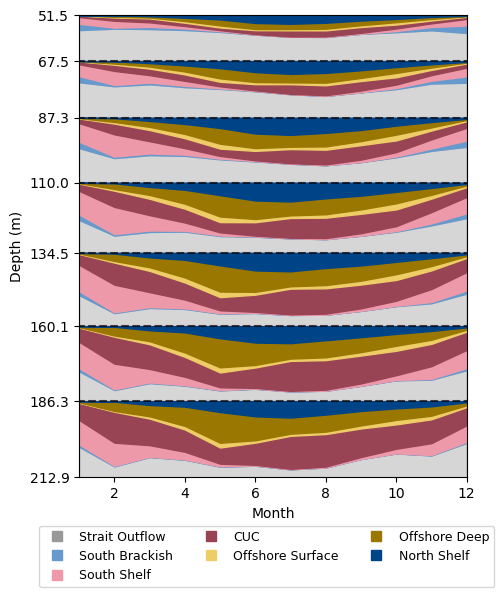

In [7]:
fig, ax = plt.subplots(1,1,figsize=[5,6])

ax.set_xlim([1,12])
ax.set_ylim([depthsep[-1],depthsep[0]])
# ax.hlines(xmin=0,xmax=13,y=50,colors='k',linestyles='dashed',alpha=0.7)
ax.hlines(xmin=0,xmax=13,y=depthsep[1],colors='k',linestyles='dashed',alpha=0.7)
ax.hlines(xmin=0,xmax=13,y=depthsep[2],colors='k',linestyles='dashed',alpha=0.7)
ax.hlines(xmin=0,xmax=13,y=depthsep[3],colors='k',linestyles='dashed',alpha=0.7)
ax.hlines(xmin=0,xmax=13,y=depthsep[4],colors='k',linestyles='dashed',alpha=0.7)
ax.hlines(xmin=0,xmax=13,y=depthsep[5],colors='k',linestyles='dashed',alpha=0.7)
ax.hlines(xmin=0,xmax=13,y=depthsep[6],colors='k',linestyles='dashed',alpha=0.7)
ax.set_yticks(depthsep)

ax.set_ylabel('Depth (m)')
ax.set_xlabel('Month')

# insert legend
legend_handles = []
colours = ['#999999','#6699CC','#EE99AA','#994455','#EECC66','#997700','#004488']
currents = ['Strait Outflow','South Brackish','South Shelf','CUC','Offshore Surface','Offshore Deep','North Shelf']
for i in range(len(currents)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker='s', linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],
                          label=currents[i]))
# Add a figure-wide legend below the subplots
fig.legend(handles=legend_handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 0.04), frameon=True,fontsize=9)

for i in range(len(columns)):
    loo = depthsep[i+1]-(looclim[columns[i]])*(depthsep[i+1]-depthsep[i])
    cuc = (cucclim[columns[i]])*(depthsep[i+1]-depthsep[i])
    fre = (freclim[columns[i]])*(depthsep[i+1]-depthsep[i])
    sou = (souclim[columns[i]])*(depthsep[i+1]-depthsep[i])
    ofD = (ofDclim[columns[i]])*(depthsep[i+1]-depthsep[i])
    ofS = (ofSclim[columns[i]])*(depthsep[i+1]-depthsep[i])
    nor = (norclim[columns[i]])*(depthsep[i+1]-depthsep[i])

    ax.fill_between(np.arange(1,12+1),y1=loo,y2=depthsep[i+1],color='#999999',alpha=0.4)
    ax.fill_between(np.arange(1,12+1),y1=loo-fre,y2=loo,color='#6699CC')
    ax.fill_between(np.arange(1,12+1),y1=loo-fre-sou,y2=loo-fre,color='#EE99AA')
    ax.fill_between(np.arange(1,12+1),y1=loo-fre-sou-cuc,y2=loo-fre-sou,color='#994455')
    ax.fill_between(np.arange(1,12+1),y1=loo-fre-sou-cuc-ofS,y2=loo-fre-sou-cuc,color='#EECC66')
    ax.fill_between(np.arange(1,12+1),y1=loo-fre-sou-cuc-ofS-ofD,y2=loo-fre-sou-cuc-ofS,color='#997700')
    ax.fill_between(np.arange(1,12+1),y1=loo-fre-sou-cuc-ofS-ofD-nor,y2=loo-fre-sou-cuc-ofS-ofD,color='#004488')

# plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/projections/figures/contribution.png', bbox_inches='tight')

In [8]:
# simpler visually to show the mean contribution over this range
d = {'month':np.arange(1,13,1),'loop':np.full(12,fill_value=np.nan),'fresh':np.full(12,fill_value=np.nan),
     'south':np.full(12,fill_value=np.nan),'cuc':np.full(12,fill_value=np.nan),'offS':np.full(12,fill_value=np.nan),
     'offD':np.full(12,fill_value=np.nan),'north':np.full(12,fill_value=np.nan)}
data = pd.DataFrame(d)
data

for i in range(12):
    data.loc[i,'loop'] = np.average(looclim[looclim.index==i+1].values[0],weights=cellheight)
    data.loc[i,'fresh'] = np.average(freclim[freclim.index==i+1].values[0],weights=cellheight)
    data.loc[i,'south'] = np.average(souclim[souclim.index==i+1].values[0],weights=cellheight)
    data.loc[i,'cuc'] = np.average(cucclim[cucclim.index==i+1].values[0],weights=cellheight)
    data.loc[i,'offS'] = np.average(ofSclim[ofSclim.index==i+1].values[0],weights=cellheight)
    data.loc[i,'offD'] = np.average(ofDclim[ofDclim.index==i+1].values[0],weights=cellheight)
    data.loc[i,'north'] = np.average(norclim[norclim.index==i+1].values[0],weights=cellheight)

data

,month,loop,fresh,south,cuc,offS,offD,north
0,1,0.487466,0.073364,0.298407,0.126568,0.005296,0.007997,0.000903
1,2,0.304403,0.016180,0.317809,0.252158,0.018920,0.082968,0.007563
2,3,0.368772,0.019207,0.172163,0.239754,0.040665,0.109960,0.049480
3,4,0.346316,0.013864,0.101551,0.201214,0.057998,0.195113,0.083944
4,5,0.285766,0.007953,0.036958,0.149417,0.067987,0.301760,0.150159
5,6,0.275890,0.003423,0.010682,0.200600,0.036748,0.252905,0.219752
6,7,0.238143,0.001272,0.006371,0.299595,0.032358,0.185713,0.236548
7,8,0.235586,0.000447,0.012542,0.300102,0.041807,0.208884,0.200633
8,9,0.301399,0.000679,0.031156,0.280314,0.051206,0.176965,0.158280
9,10,0.365148,0.009145,0.064915,0.236645,0.073219,0.141373,0.109555


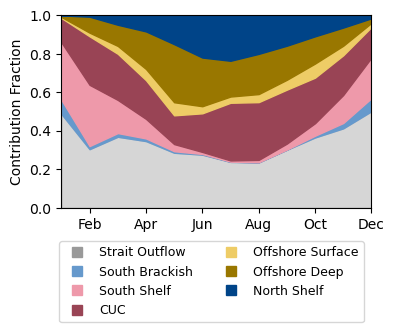

In [10]:
fig, ax = plt.subplots(1,1,figsize=[4,2.5])

ax.set_xlim([1,12])
ax.set_ylim([0,1])

ax.set_ylabel('Contribution Fraction')
# ax.set_xlabel('Month')
ax.set_xticks([2,4,6,8,10,12])
ax.set_xticklabels(['Feb','Apr','Jun','Aug','Oct','Dec'])

# insert legend
legend_handles = []
colours = ['#999999','#6699CC','#EE99AA','#994455','#EECC66','#997700','#004488']
currents = ['Strait Outflow','South Brackish','South Shelf','CUC','Offshore Surface','Offshore Deep','North Shelf']
for i in range(len(currents)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker='s', linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],
                          label=currents[i]))
# Add a figure-wide legend below the subplots
fig.legend(handles=legend_handles, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.001), frameon=True,fontsize=9)

#plotting
ax.fill_between(np.arange(1,12+1),y1=data.loop,y2=0,color='#999999',alpha=0.4)
ax.fill_between(np.arange(1,12+1),y1=data.loop+data.fresh,y2=data.loop,color='#6699CC')
ax.fill_between(np.arange(1,12+1),y1=data.loop+data.fresh+data.south,y2=data.loop+data.fresh,color='#EE99AA')
ax.fill_between(np.arange(1,12+1),y1=data.loop+data.fresh+data.south+data.cuc,y2=data.loop+data.fresh+data.south,color='#994455')
ax.fill_between(np.arange(1,12+1),y1=data.loop+data.fresh+data.south+data.cuc+data.offS,y2=data.loop+data.fresh+data.south+data.cuc,color='#EECC66')
ax.fill_between(np.arange(1,12+1),y1=data.loop+data.fresh+data.south+data.cuc+data.offS+data.offD,y2=data.loop+data.fresh+data.south+data.cuc+data.offS,color='#997700')
ax.fill_between(np.arange(1,12+1),y1=data.loop+data.fresh+data.south+data.cuc+data.offS+data.offD+data.north,y2=data.loop+data.fresh+data.south+data.cuc+data.offS+data.offD,color='#004488')

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/projections/figures/contribution.png', bbox_inches='tight')